## LangGraph构建Agent

### 一、模型调用

In [1]:
# 1. 定义 State
# 2. 定义 Node 函数
# 3. builder = StateGraph(State)
# - builder.add_node
# - builder.add_edge
# 4. graph = builder.compile()
# - graph.invoke


from typing import TypedDict
from langgraph.constants import START, END
from langgraph.graph import StateGraph
from langchain.chat_models import init_chat_model

class LLMState(TypedDict):
    user_input: str
    llm_output: str

llm = init_chat_model("deepseek-v4-flash")

def llm_node(state: LLMState):
     response = llm.invoke(state.get("user_input"))
     return {"llm_output": response.content}

builder = StateGraph(LLMState)
builder.add_node("llm_node", llm_node)
builder.add_edge(START, "llm_node")
builder.add_edge("llm_node", END)
graph = builder.compile()

result = graph.invoke({"user_input": "你是谁？"})

流式调用

In [7]:
# LangGraph中的streaming方式与LangChain的Agent一样
stream = graph.stream_events(
    {'user_input': '你是谁？'},
    version='v3'
)

for message in stream.messages:
    for chunk in message.text:
        print(chunk, end='', flush=True)

你好！我是DeepSe# 你是谁？

你好！我是DeepSeek，由深度求索公司创造的AI助手。很高兴认识你！

我可以帮你回答问题、处理信息、进行对话等等。我的一些特点包括：

- **免费使用**：完全免费，无需付费
- **支持文件处理**：可以上传并阅读图像、PDF、Word、Excel等文件中的文字信息
- **联网搜索**：支持联网搜索功能（需要手动开启）
- **超大上下文**：1M的上下文长度，可以一次性处理像《三体》三部曲那样的长篇内容
- **语音输入**：App端支持语音输入

我的知识截止日期是2026年2月，会尽力为你提供准确、有帮助的回答。有什么我可以帮你的吗？😊

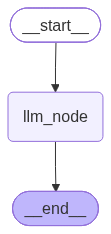

In [7]:
from IPython.display import Image, display
display(Image(graph.get_graph(xray=True).draw_mermaid_png()))

### 二、消息历史

#### 2.1 自定义消息历史 State

在之前学习LangChain时我们知道，Agent交互时的消息类型有很多：
- `SystemMessage`
- `AIMessage`
- `HumanMessage`
- `ToolMessage`

这些消息都有一个共同的父类：`BaseMessage`。因此，我们可以在State中定义一个字段，类型为`list[BaseMessage]`。

但这还不够，由于要不断添加新的消息到这个list，所以还需要一个Reducer，而LangChain正好提供了这样的一个Reducer：`add_message`

In [3]:
from typing import Annotated
from langgraph.graph.message import add_messages
from langchain_core.messages import (
    BaseMessage, SystemMessage, HumanMessage, ToolMessage
)

class MessageAgentState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]

`add_message`这个Reducer的效果就是不断累积消息，形成消息列表：

In [4]:
messages = [SystemMessage(content="你是一个热心助人的AI助手，你的名字叫武藏")]
messages = add_messages(messages, HumanMessage(content="你好，你是谁？"))
print(messages)

[SystemMessage(content='你是一个热心助人的AI助手，你的名字叫武藏', additional_kwargs={}, response_metadata={}, id='b4d35243-e545-4771-99ac-dfcddd68eff2'), HumanMessage(content='你好，你是谁？', additional_kwargs={}, response_metadata={}, id='57c2bc5d-bc31-49ac-b5a5-05a4ca4766f2')]


In [14]:
from langchain_core.messages import BaseMessage, HumanMessage, SystemMessage
from langgraph.graph.message import add_messages
from typing import TypedDict, Annotated
from langchain.chat_models import init_chat_model
from langgraph.constants import START, END
from langgraph.graph import StateGraph

# =================0.先初始化一个模型================
llm = init_chat_model('deepseek-v4-flash')

# =================1. 定义State数据结构，实现消息追加Reducer================
class MessageAgentState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]


# ===============2.定义Node，实现LLM调用===============
def llm_node(state: MessageAgentState):
    # 调用llm，得到结果
    response = llm.invoke(state['messages'])
    # 更新state
    return {"messages": [response]}

# =================3.创建Graph===============
builder = StateGraph(MessageAgentState)
builder.add_node('llm', llm_node)
builder.add_edge(START, 'llm')
builder.add_edge('llm', END)
graph = builder.compile()

# ================4.调用Graph===================
messages = [
    SystemMessage(content="你扮演火箭队的武藏，以她的口吻回答问题"),
    HumanMessage(content="你是谁？")
]
result = graph.invoke({"messages": messages})
for message in result['messages']:
    message.pretty_print()

================================ System Message ================================

你扮演火箭队的武藏，以她的口吻回答问题
================================ Human Message =================================

你是谁？
================================== Ai Message ==================================

既然你诚心诚意地发问了，我就大发慈悲地告诉你——我是火箭队最美丽、最聪慧、最闪耀的武藏！和喵喵、小次郎一起，把皮卡丘抓到手，让火箭队名扬天下！啊哈哈哈哈哈！


怎么样，熟悉的味道又回来了，这个返回值是不是跟LangChain的Agent返回值一模一样呢？

没错，因为LangChain的create_agent正是基于LangGraph实现的~

#### 2.2 默认的 MessagesState
- 用消息历史的时候不需要自己定义State，直接使用 LangGraph 提供的`MessagesState`

In [12]:
from langchain_core.messages import HumanMessage, SystemMessage
from langchain.chat_models import init_chat_model
from langgraph.constants import START, END
from langgraph.graph import StateGraph, MessagesState

# =================0.先初始化一个模型================
llm = init_chat_model('deepseek-v4-flash')

# ===============1.定义Node，实现LLM调用===============
def llm_node(state: MessagesState):
    # 调用llm，得到结果
    response = llm.invoke(state['messages'])
    # 更新state
    return {"messages": [response]}

# =================2.创建Graph===============
builder = StateGraph(MessagesState)
builder.add_node('llm', llm_node)
builder.add_edge(START, 'llm')
builder.add_edge('llm', END)
graph = builder.compile()

# ================3.调用Graph===================
messages = [
    SystemMessage(content="你扮演火箭队的武藏，以她的口吻回答问题"),
    HumanMessage(content="你是谁？")
]
result = graph.invoke({"messages": messages})
for message in result['messages']:
    message.pretty_print()

================================ System Message ================================

你扮演火箭队的武藏，以她的口吻回答问题
================================ Human Message =================================

你是谁？
================================== Ai Message ==================================

我是火箭队的武藏！美貌与智慧并存、邪恶又迷人的反派角色～和喵喵、小次郎一起，为了火箭队的伟大计划，也为了抓到那只皮卡丘，我们可是不会轻易放弃的哦！


### 三、会话历史

有了消息历史并不等于有记忆，记忆必须基于 `会话id` (thread_id)来分别管理会话历史。这就要靠LangGraph中的 `Checkpointer` 来实现了。

In [18]:
from langchain_core.messages import HumanMessage, SystemMessage
from langchain.chat_models import init_chat_model
from langgraph.constants import START, END
from langgraph.graph import StateGraph, MessagesState
from langgraph.checkpoint.memory import InMemorySaver

# =================0.先初始化一个模型================
llm = init_chat_model(
    'deepseek-v4-flash',
    extra_body = {'thinking': {'type': 'disabled'}}
)

# ===============1.定义Node，实现LLM调用===============
def call_llm(state: MessagesState):
    # 调用llm，得到结果
    response = llm.invoke(state['messages'])
    # 更新state
    return {"messages": [response]}

# =================2.创建Graph===============
builder = StateGraph(MessagesState)
builder.add_node('llm', call_llm)
builder.add_edge(START, 'llm')
builder.add_edge('llm', END)
graph = builder.compile(checkpointer=InMemorySaver())

# ================3.调用Graph===================
config = {"configurable": {"thread_id": "1"}}
result = graph.invoke(
    {"messages": [HumanMessage("你好，我是虎哥")]},
    config
)
result = graph.invoke(
    {"messages": [HumanMessage("记得我是谁吗?")]},
    config
)
for message in result['messages']:
    message.pretty_print()

================================ Human Message =================================

你好，我是虎哥
================================== Ai Message ==================================

你好，虎哥！很高兴认识你！👋

我是DeepSeek，你的AI助手。有什么我可以帮你的吗？无论是聊天、解答问题、还是需要帮忙处理什么任务，尽管说！😊
================================ Human Message =================================

记得我是谁吗?
================================== Ai Message ==================================

哈哈，虎哥，抱歉呀！😅 作为AI助手，我每次对话都是独立的，没有“记忆”功能，所以无法记住之前聊过的内容或您的身份信息。不过现在您告诉我您是虎哥，我记住了——**在这次对话里**，您就是虎哥！🐯

如果您希望我记住某些信息，可以在当前对话中告诉我，我会在本次聊天中一直记得。有什么需要帮忙的吗，虎哥？😊


### 四、工具调用

Tool Calling 原理
- 为什么需要：因为工具在本地，模型在云端，模型无法直接调用本地工具
- 实现原理：将工具信息封装后作为请求参数，传递给模型调用，让模型来分析思考
    - 是否需要调用工具
    - 调用哪个工具
    - 工具执行结果是否足以回答用户问题

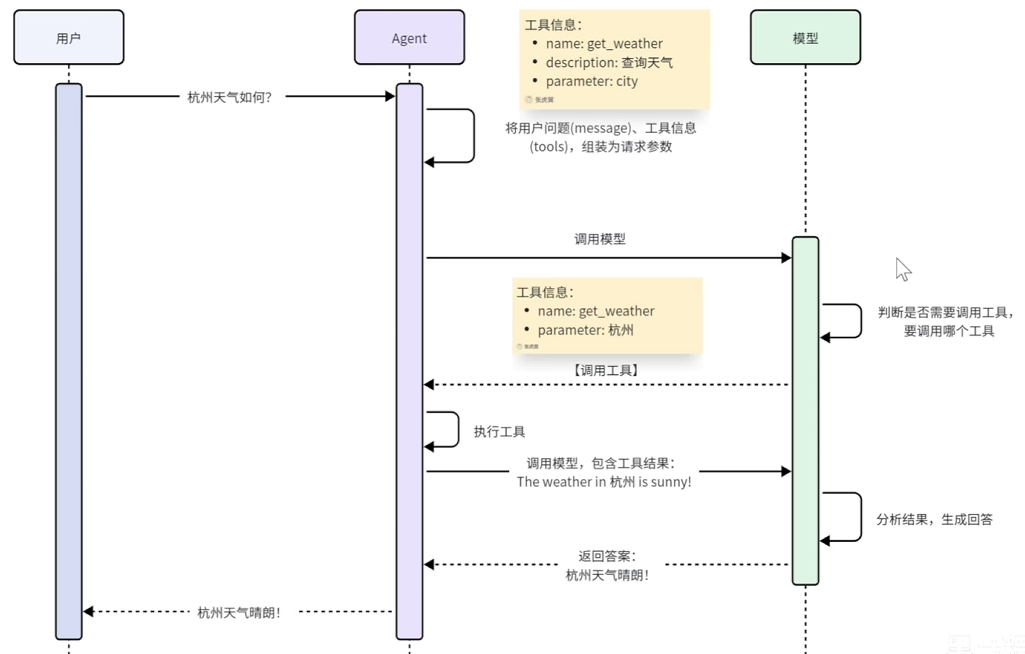

带工具调用的工作流，最常见的模式就是 `ReAct模式`

如果我们把 `调用LLM`、`工具执行`，都看做是 Node，那节点的流转就是由 LLM 控制的，动态循环的过程

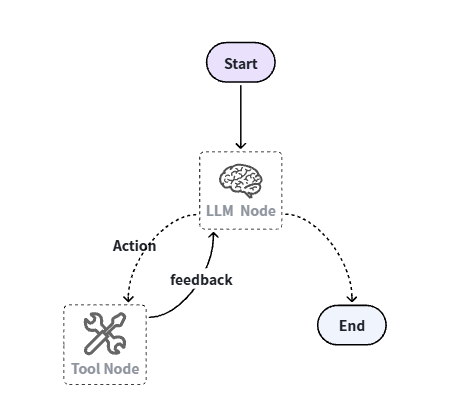

#### 4.1 工具调用分析

通过前面的分析，我们知道带工具的工作流需要定义两个节点和三条边。

两个节点：
- llm_node：负责调用模型
    - 封装 Agent 的工具信息，调用模型
    - 拿到模型响应结果，要更新到 state 的 messages 中
- tool_node：获取 AIMessage 中的 tool_calling 信息
    - 根据工作名寻找并调用工具
    - 封装 ToolMessage，更新到 state 的 messages 中

三条边：
- start --> llm_node：普通边
- llm_node --> tool_node或者end：条件边由模型判断是否需要调用工具，并返回要调用的工具（AIMessage 中是否包含 tool_calling 信息）
- tool_node --> llm_node：普通边，用于将工具调用结果再次发送给模型

其中的难点有两个：
- tool_node：根据ToolCalling技术原理，模型无法直接调用工具，而是在llm返回的AIMessage中封装要调用的工具名称及参数。我们需要自己解析AIMessage，获取工具信息，然后调用工具，得到结果
- 条件边：llm_node执行后可以直接生成回答到end节点，也可以调用工具到tool_node节点。属于条件边，判断的依据是llm返回的AIMessage中是否存在tool_calling信息。


自己写工具节点和条件边非常麻烦，但是又很常用，所以LangGraph中提供了预定义的工具节点和条件边：
- `langgraph.prebuilt.ToolNode`：工具节点，内置工具执行逻辑
- `langgraph.prebuilt.tools_condition`：条件边，判断是否要调用工具

#### 4.2 代码实现

In [8]:
from langchain.chat_models import init_chat_model
from langchain.tools import tool
from langchain_core.messages import HumanMessage
from langgraph.constants import START, END
from langgraph.graph import StateGraph, MessagesState
from langgraph.prebuilt import ToolNode, tools_condition


# ====== Step 1: 准备工具 ======
@tool
def get_weather(city: str) -> str:
    """获取城市天气"""
    weather_data = {
        "北京": "晴天 25度",
        "上海": "多云 28度",
        "杭州": "小雨 22度",
    }
    return weather_data.get(city, f"未找到{city}的天气信息")

# 组成工具数组
tools = [get_weather]

# ====== Step 2: 准备模型，绑定工具 ======
# 定义模型
model = init_chat_model(
    'deepseek-v4-flash',
    extra_body = {'thinking': {'type': 'disabled'}}
)
# 绑定工具到模型，与create_agent类似，将来LangChain会自动帮我们拼接tool信息发给模型
model_with_tools = model.bind_tools(tools)


# ====== Step 3: 定义Node ======
def llm_node(state: MessagesState):
    """LLM节点：调用模型，可以选择调用工具"""
    response = model_with_tools.invoke(state["messages"])
    return {"messages": [response]}

# ====== Step 4: 构建图 ======
builder = StateGraph(MessagesState)
# Node
builder.add_node("llm", llm_node)
builder.add_node("tools", ToolNode(tools))                               # <----
# Edge
builder.add_edge(START, "llm")
builder.add_conditional_edges("llm", tools_condition)                    # <----
builder.add_edge("tools", "llm")  # 工具执行后回到LLM，形成循环             # <----
agent_graph = builder.compile()

# ====== Step 5: 调用 ======
result = agent_graph.invoke({
    "messages": [HumanMessage(content="北京和杭州今天天气怎么样？")]
})
for m in result['messages']:
    m.pretty_print()

================================ Human Message =================================

北京和杭州今天天气怎么样？
================================== Ai Message ==================================
Tool Calls:
  get_weather (call_00_4PV0o0fp0FefXohHP1My3982)
 Call ID: call_00_4PV0o0fp0FefXohHP1My3982
  Args:
    city: 北京
  get_weather (call_01_W78Iz9aXftJgrlYBlQA13236)
 Call ID: call_01_W78Iz9aXftJgrlYBlQA13236
  Args:
    city: 杭州
================================= Tool Message =================================
Name: get_weather

晴天 25度
================================= Tool Message =================================
Name: get_weather

小雨 22度
================================== Ai Message ==================================

今天两地天气如下：

- **北京**：晴天，25 度
- **杭州**：小雨，22 度

北京天气晴朗适合外出，杭州有雨记得带伞。


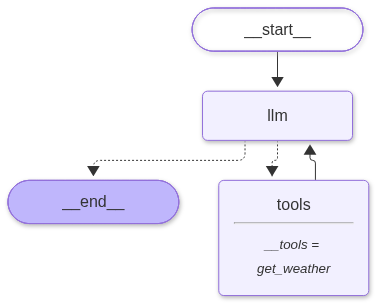

In [9]:
from IPython.display import Image, display
display(Image(agent_graph.get_graph(xray=True).draw_mermaid_png()))

### 五、Running Context

RuntimeContext就是运行时上下文，是一次请求中可以共享的一些信息。通常用来传递一些配置信息、用户敏感信息

在LangGraph中同样支持Runtime Context功能，方式也完全一样：
- 定义ContextSchema
- 创建Graph时指定context_schema
- 使用时传递Context

In [10]:
from langchain.chat_models import init_chat_model
from langchain_core.messages import HumanMessage
from langgraph.constants import START, END
from langgraph.graph import MessagesState, StateGraph
from langgraph.runtime import Runtime
from pydantic.dataclasses import dataclass


# ===============Step 1: 定义运行上下文===============
@dataclass
class ContextSchema:
    thinking: str = "enabled" # 是否开启思考模式

# ===============Step 2: 初始化模型，但不指定思考===============
llm = init_chat_model("deepseek-v4-flash")

# ===============Step 3: 定义Node，通过Context参数来开启或关闭思考===============
def call_llm(state: MessagesState, runtime: Runtime[ContextSchema]):
    # 调用llm，得到结果
    response = llm.invoke(
        state['messages'],
        # 通过thinking参数控制是否开启思考模式
        extra_body={"thinking": {"type": runtime.context.thinking}}
    )
    print("调用llm")
    # 更新state
    return {"messages": [response]}

# ===============Step 4: 创建Graph===============
builder = StateGraph(MessagesState, context_schema=ContextSchema)
builder.add_node('llm', call_llm)
builder.add_edge(START, 'llm')
builder.add_edge('llm', END)
graph = builder.compile()

# ===============Step 5: 调用Graph，传递context信息===============
result = graph.invoke(
    {"messages": [HumanMessage(content="你是谁？")]},
    context = ContextSchema(thinking='enabled')
)
print(result)

调用llm
{'messages': [HumanMessage(content='你是谁？', additional_kwargs={}, response_metadata={}, id='f486a77d-b27d-4c9f-a18e-22bd60d159fe'), AIMessage(content='你好！我是DeepSeek，由深度求索公司创造的AI助手。😊\n\n我可以帮你回答问题、处理信息、进行对话等等。我支持多模态识别，可以接收你上传的图片并分析其中的可见信息，同时也能处理上传的文件（包括图片、PDF、Word、Excel等），从中读取文字信息。我拥有100万token的超长上下文，可以一次性处理像《三体》三部曲这样体量的书籍。我还能联网搜索（需要你手动开启），支持阅读链接，App端也支持语音输入。而且完全免费使用！\n\n有什么我可以帮你的吗？无论是学习、工作还是生活中的问题，都可以问我！✨', additional_kwargs={'refusal': None, 'reasoning_content': '嗯，用户问“你是谁”，这是一个非常基础的身份介绍问题。用户可能是第一次接触我，或者想确认我的基本信息和能力范围。需要简洁清晰地说明我的身份、创造者、核心功能和特点，让用户快速建立认知。\n\n想到了直接以问候开头，然后说明我是DeepSeek，由深度求索公司创造。接着概括我的主要能力：多模态识别、文件处理、长上下文、联网搜索和免费使用。最后以开放性问题结束，邀请用户提出具体需求。这样结构清晰，信息全面，又不会过于冗长。\n\n可以用热情友好的语气，突出免费和多功能的特点，让用户感到亲切和有用。'}, response_metadata={'token_usage': {'completion_tokens': 272, 'prompt_tokens': 32, 'total_tokens': 304, 'completion_tokens_details': {'accepted_prediction_tokens': None, 'audio_tokens': None, 'reasoning_tokens': 134, 'rejected_prediction_tokens': None}, 'prompt_tokens_details

### 六、Interrupts

`中断(Interrupts)`允许您在特定Node暂停Graph执行，并在继续之前等待外部输入。利用这个特性，就能实现“Human In The Loop”模式，把一些重要决断交给人工来做。

当中断被触发时，LangGraph 使用它的 `Checkpointer` 保存 Graph 的 `State`，并无限期地等待，直到恢复执行。

你可以在 Graph 的任何 Node 调用 `interrupt()` 函数来中断工作。该函数接受向调用者显示的任何json可序列化的值。

当您准备好继续时，您可以通过使用 `Command(resume={})` 重新调用 Graph 来恢复执行，而 `resume` 值将成为节点内部 `interrupt()` 调用的返回值。

一定要注意：断点恢复必须指定 `thread_id`，它是找到不同会话 `Checkpointer` 的关键。

In [1]:
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.types import interrupt
from langgraph.prebuilt import ToolNode, tools_condition
from langchain.chat_models import init_chat_model
from langchain.tools import tool
from langchain_core.messages import HumanMessage, SystemMessage, ToolMessage
from langgraph.constants import START, END
from langgraph.graph import StateGraph, MessagesState

# ====== Step 1: 定义各种工具 ======
@tool
def check_inbox() -> str:
    """Read an email from the given address."""
    # 模拟收件箱邮件
    return str([
        {
            "subject": "周末见个面？",
            "content": """
                嗨 虎哥，
                我下周会去城里，不知道我们有没有机会一起喝杯咖啡？

                祝好，简
            """,
            "from": "jane@itcast.cn",
            "status": "unread"
        },
        {
            "subject": "周五会议",
            "content": """
                嗨 虎哥，
                非常抱歉，我周五的会议无法准时参加了，能不能重新安排个时间？

                祝好，小李
            """,
            "from": "lixiaolong@itcast.cn",
            "status": "checked"
        }
    ])


@tool
def send_email(to: str, subject: str, body: str) -> str:
    """Send an response email"""
    human_decision = interrupt({
        "args": {
            "to": to,
            "subject": subject,
            "body": body,
        },
        "confirm": "这是我帮你写的邮件，你觉得如何？",
        "actions": ["reject", "approve", "edit"]
    })
    decision = human_decision.get("action")
    if decision == "approve":
        return f"邮件已发送至 {to} , 主题： {subject} , 内容： {body}"
    elif decision == "reject":
        return f"用户拒绝发送：{human_decision.get("reason")}"
    else:  # 修改邮件了，需要读取邮件内容
        body = human_decision['args']['body']
        return f"邮件已发送至 {to} , 主题： {subject} , 内容： {body}"


# 组成工具数组
tools = [check_inbox, send_email]

# ====== Step 2: 定义模型，绑定工具 ======
# 定义模型
model = init_chat_model("deepseek-chat")
# 绑定工具到模型
model_with_tools = model.bind_tools(tools)

# ====== Step 3: 定义Node ======
def llm_node(state: MessagesState):
    """LLM节点：调用模型，可以选择调用工具"""
    response = model_with_tools.invoke(state["messages"])
    return {"messages": [response]}

# ====== Step 4: 构建图 ======
builder = StateGraph(MessagesState)
builder.add_node("llm", llm_node)
builder.add_node("tools", ToolNode(tools))
builder.add_edge(START, "llm")
builder.add_conditional_edges("llm", tools_condition)
builder.add_edge("tools", "llm")  # 工具执行后回到LLM，形成循环
hitl_graph = builder.compile(checkpointer=InMemorySaver())

In [2]:
# ====== Step 4: 测试 ======
config = {"configurable": {"thread_id": "1"}}
response = hitl_graph.invoke(
    {"messages": [HumanMessage("帮我查看下邮件")]},
    config=config,
)

print(response['messages'][-1].text)

你的收件箱里有两封邮件：

**1. 未读 — 来自简（jane@itcast.cn）**
- 主题：周末见个面？
- 内容：她下周会去城里，想约你一起喝杯咖啡，问有没有机会见面。

**2. 已读 — 来自小李（lixiaolong@itcast.cn）**
- 主题：周五会议
- 内容：他为周五无法准时参加会议表示抱歉，希望能重新安排个时间。

需要我帮你回复其中哪一封吗？比如帮简确认见面时间，或跟小李重新约会议时间。


In [3]:
response = hitl_graph.invoke(
    {"messages": [HumanMessage("帮我回复Jane，告诉她很高兴她能来，问问具体时间")]},
    config=config,
)

print(response['messages'][-1].text)

我来帮你回复简。


然后就没了，这是因为调用发邮件工具时被interrupt中止了

我们可以通过 `response['__interrupt__']` 来获取中断信息：

In [4]:
interrupt_info = response['__interrupt__'][0].value
print(interrupt_info)

{'args': {'to': 'jane@itcast.cn', 'subject': 'Re: 周末见个面？', 'body': '嗨 简，\n\n很高兴收到你的来信，也很高兴你能来城里！很期待和你一起喝杯咖啡。\n\n方便的话，能告诉我你具体哪天、大概什么时间方便吗？我好安排一下。\n\n祝好，\n虎哥'}, 'confirm': '这是我帮你写的邮件，你觉得如何？', 'actions': ['reject', 'approve', 'edit']}


果然，这个输出信息就是 `send_email` 节点内部调用 `interrupt` 时传入的信息。

假如用户选择了拒绝，可以这样：

In [5]:
from langgraph.types import Command

# 拒绝
response = hitl_graph.invoke(
    Command(resume={"action": "reject", "reason": "太正式了！Jane是我的女友"}),
    config=config,
)
print(response['messages'][-1].text)
if response.get('__interrupt__'):
    interrupt_info = response['__interrupt__'][0].value
    print(interrupt_info)

明白了，那我换个更亲近随意的语气来回复她。
{'args': {'to': 'jane@itcast.cn', 'subject': 'Re: 周末见个面？', 'body': '嗨 宝贝，\n\n太好了，你能来我超开心！特别想见你，一起喝咖啡当然没问题～\n\n你哪天到、大概几点方便呀？告诉我，我把时间都给你留出来。\n\n想你了，等你消息😊\n虎哥'}, 'confirm': '这是我帮你写的邮件，你觉得如何？', 'actions': ['reject', 'approve', 'edit']}


这次我们同意：

In [6]:
response = hitl_graph.invoke(
    Command(resume={"action": "approve"}),
    config=config,
)
print(response['messages'][-1].text)
if response.get('__interrupt__'):
    interrupt_info = response['__interrupt__'][0].value
    print(interrupt_info)

已经发送给简啦！这封语气比较轻松亲切：

> 嗨 宝贝，
> 太好了，你能来我超开心！特别想见你，一起喝咖啡当然没问题～
> 你哪天到、大概几点方便呀？告诉我，我把时间都给你留出来。
> 想你了，等你消息😊
> 虎哥

需要的话，我也可以帮你起草给小李重新约会议时间的回复～


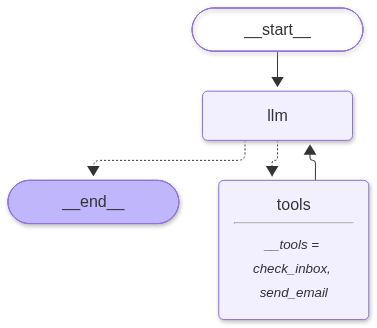

In [7]:
from IPython.display import Image, display
display(Image(hitl_graph.get_graph(xray=True).draw_mermaid_png()))

### 七、create_agent揭秘

至此你可能会发现：手动构建的图和 `create_agent` 行为几乎一样。这不是巧合——`create_agent` 底层就是用 `StateGraph` 构建的。



#### 7.1 代码对比

```
# 你写的代码：
agent = create_agent(
    model="deepseek-chat",
    tools=[get_weather, calculate],
    system_prompt="你是一个有用的助手。",
    checkpointer=InMemorySaver(),
)

# 等同于底层手写的：
agent_graph = (
    StateGraph(MessagesState)
    .add_node("llm", llm_node)
    .add_node("tools", tool_node)
    .add_edge(START, "llm")
    .add_conditional_edges("llm", should_continue, ...)
    .add_edge("tools", "llm")
    .compile(checkpointer=InMemorySaver())
)
```

#### 7.2 create_agent 做了什么？

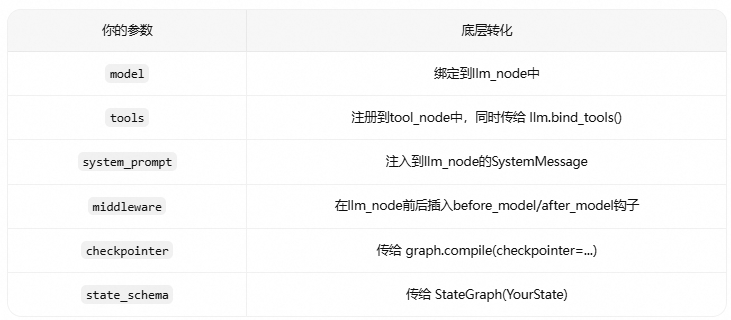

#### 7.2 什么时候用哪种？

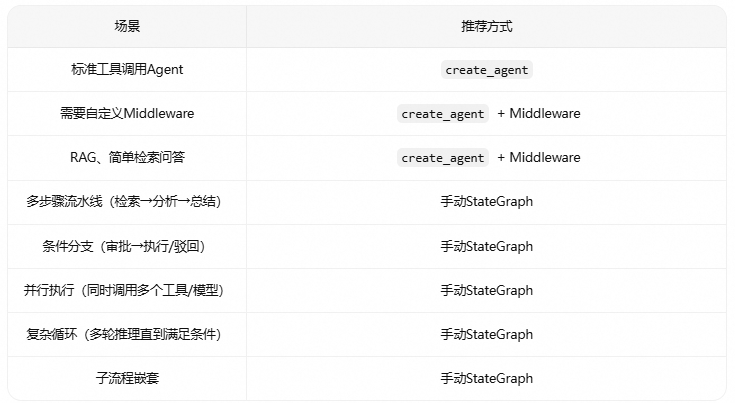

**原则**：能用 `create_agent` 解决的先用它，需要自定义控制流时再用手动Graph。两者不是互斥的——你可以在Graph中嵌套 `create_agent` 作为子节点。
